In [5]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [10]:
BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\02_Model_Comparison")
root_dir = BASE_DIR/"hasil_train_yolo"


folder_v8 = os.path.join(root_dir, "train-yolov8")
folder_v9 = os.path.join(root_dir, "train-yolov9t")
folder_v10 = os.path.join(root_dir, "train-yolov10")
folder_v11 = os.path.join(root_dir, "train-yolov11")
folder_v12 = os.path.join(root_dir, "train-yolov12")
folder_yolo26 = os.path.join(root_dir, "train-yolo26")

output_dir = os.path.join(root_dir, "model-comparison-output")
os.makedirs(output_dir, exist_ok=True)

# cek folder model
print("Pengecekan folder model:")
print("YOLOv8  :", os.path.exists(folder_v8))
print("YOLOv9  :", os.path.exists(folder_v9))
print("YOLOv10 :", os.path.exists(folder_v10))
print("YOLOv11 :", os.path.exists(folder_v11))
print("YOLOv12 :", os.path.exists(folder_v12))
print("YOLO26  :", os.path.exists(folder_yolo26))

Pengecekan folder model:
YOLOv8  : True
YOLOv9  : True
YOLOv10 : True
YOLOv11 : True
YOLOv12 : True
YOLO26  : True


In [12]:
# lokasi file training

# results.csv
results_v8 = os.path.join(folder_v8, "results.csv")
results_v9 = os.path.join(folder_v9, "results.csv")
results_v10 = os.path.join(folder_v10, "results.csv")
results_v11 = os.path.join(folder_v11, "results.csv")
results_v12 = os.path.join(folder_v12, "results.csv")
results_yolo26 = os.path.join(folder_yolo26, "results.csv")

# best.pt
best_v8 = os.path.join(folder_v8, "weights", "best.pt")
best_v9 = os.path.join(folder_v9, "weights", "best.pt")
best_v10 = os.path.join(folder_v10, "weights", "best.pt")
best_v11 = os.path.join(folder_v11, "weights", "best.pt")
best_v12 = os.path.join(folder_v12, "weights", "best.pt")
best_yolo26 = os.path.join(folder_yolo26, "weights", "best.pt")

In [ ]:
# mencari file results.csv

results_v8 = glob.glob(os.path.join(folder_v8, "**", "results.csv"), recursive=True)
results_v9 = glob.glob(os.path.join(folder_v9, "**", "results.csv"), recursive=True)
results_v10 = glob.glob(os.path.join(folder_v10, "**", "results.csv"), recursive=True)
results_v11 = glob.glob(os.path.join(folder_v11, "**", "results.csv"), recursive=True)
results_v12 = glob.glob(os.path.join(folder_v12, "**", "results.csv"), recursive=True)
results_yolo26 = glob.glob(os.path.join(folder_yolo26, "**", "results.csv"), recursive=True)

print("YOLOv8  :", results_v8)
print("YOLOv9  :", results_v9)
print("YOLOv10 :", results_v10)
print("YOLOv11 :", results_v11)
print("YOLOv12 :", results_v12)
print("YOLO26  :", results_yolo26)


YOLOv8  : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_train_yolo\\train-yolov8\\runs\\yolov8-cctv\\results.csv']
YOLOv9  : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_train_yolo\\train-yolov9t\\runs\\yolov9t-cctv\\results.csv']
YOLOv10 : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_train_yolo\\train-yolov10\\runs\\yolov10n-cctv\\results.csv']
YOLOv11 : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_train_yolo\\train-yolov11\\runs\\yolov11n-cctv\\results.csv']
YOLOv12 : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_train_yolo\\train-yolov12\\runs\\yolov12n-cctv\\results.csv']
YOLO26  : ['D:\\1-Kuliah\\SEKRIPSI\\Skripsi_Traffic_Density_Estimation_and_Forecasting\\02_Model_Comparison\\hasil_trai

In [14]:
# membaca results.csv

data_v8 = pd.read_csv(results_v8[0])
data_v9 = pd.read_csv(results_v9[0])
data_v10 = pd.read_csv(results_v10[0])
data_v11 = pd.read_csv(results_v11[0])
data_v12 = pd.read_csv(results_v12[0])
data_yolo26 = pd.read_csv(results_yolo26[0])


print("Semua results.csv berhasil dibaca.")

Semua results.csv berhasil dibaca.


In [15]:
# mengambil best epoch setiap model

best_v8 = data_v8.loc[data_v8["metrics/mAP50-95(B)"].idxmax()]
best_v9 = data_v9.loc[data_v9["metrics/mAP50-95(B)"].idxmax()]
best_v10 = data_v10.loc[data_v10["metrics/mAP50-95(B)"].idxmax()]
best_v11 = data_v11.loc[data_v11["metrics/mAP50-95(B)"].idxmax()]
best_v12 = data_v12.loc[data_v12["metrics/mAP50-95(B)"].idxmax()]
best_yolo26 = data_yolo26.loc[data_yolo26["metrics/mAP50-95(B)"].idxmax()]

print("Epoch terbaik setiap model berhasil diambil.")

Epoch terbaik setiap model berhasil diambil.


In [16]:
# Tabel Perbandingan Model

comparison = pd.DataFrame({
    "Model": [
        "YOLOv8n",
        "YOLOv9t",
        "YOLOv10n",
        "YOLOv11n",
        "YOLOv12n",
        "YOLO26n"
    ],

    "Best Epoch": [
        int(best_v8["epoch"]),
        int(best_v9["epoch"]),
        int(best_v10["epoch"]),
        int(best_v11["epoch"]),
        int(best_v12["epoch"]),
        int(best_yolo26["epoch"])
    ],

    "Precision": [
        best_v8["metrics/precision(B)"],
        best_v9["metrics/precision(B)"],
        best_v10["metrics/precision(B)"],
        best_v11["metrics/precision(B)"],
        best_v12["metrics/precision(B)"],
        best_yolo26["metrics/precision(B)"]
    ],

    "Recall": [
        best_v8["metrics/recall(B)"],
        best_v9["metrics/recall(B)"],
        best_v10["metrics/recall(B)"],
        best_v11["metrics/recall(B)"],
        best_v12["metrics/recall(B)"],
        best_yolo26["metrics/recall(B)"]
    ],

    "mAP50": [
        best_v8["metrics/mAP50(B)"],
        best_v9["metrics/mAP50(B)"],
        best_v10["metrics/mAP50(B)"],
        best_v11["metrics/mAP50(B)"],
        best_v12["metrics/mAP50(B)"],
        best_yolo26["metrics/mAP50(B)"]
    ],

    "mAP50-95": [
        best_v8["metrics/mAP50-95(B)"],
        best_v9["metrics/mAP50-95(B)"],
        best_v10["metrics/mAP50-95(B)"],
        best_v11["metrics/mAP50-95(B)"],
        best_v12["metrics/mAP50-95(B)"],
        best_yolo26["metrics/mAP50-95(B)"]
    ]
})

comparison.round(4)

,Model,Best Epoch,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n,87,0.9248,0.8808,0.9392,0.7526
1,YOLOv9t,98,0.9191,0.8773,0.9380,0.7509
2,YOLOv10n,90,0.9168,0.8398,0.9243,0.7386
3,YOLOv11n,99,0.9186,0.8907,0.9373,0.7500
4,YOLOv12n,85,0.9159,0.8755,0.9364,0.7577
5,YOLO26n,81,0.9241,0.8467,0.9217,0.7311


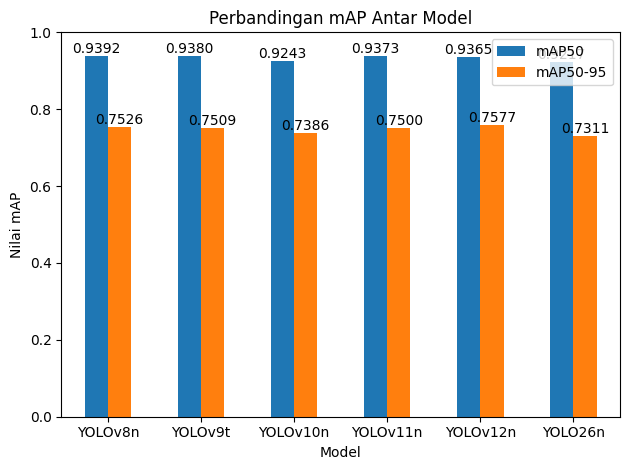

In [19]:
# Grafik Perbandingan mAP

ax = comparison.plot(
    x="Model",
    y=["mAP50", "mAP50-95"],
    kind="bar"
)

plt.title("Perbandingan mAP Antar Model")
plt.xlabel("Model")
plt.ylabel("Nilai mAP")
plt.ylim(0, 1)

plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.4f")

plt.tight_layout()
plt.show()